<a href="https://colab.research.google.com/github/iadsa/COBACOBAGIT/blob/main/DATA_TIMBUNAN_SAMPAH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **INPUT DATASET**

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

data = pd.read_excel('Data_Timbulan_Sampah_SIPSN_KLHK.xlsx', header=1)

print("=== DATA AWAL ===")
print(data.head(10))
print(f"\nKolom: {data.columns.tolist()}")
print(f"Jumlah baris: {len(data)}")
print(f"Tahun tersedia: {sorted(data['Tahun'].unique())}")
print(f"Jumlah provinsi: {data['Provinsi'].nunique()}")

=== DATA AWAL ===
   Tahun Provinsi     Kabupaten/Kota  Timbulan Sampah Harian(ton)  \
0   2025     Aceh   Kab. Aceh Tengah                       115.01   
1   2025     Aceh    Kab. Aceh Barat                        84.39   
2   2025     Aceh    Kab. Aceh Utara                       320.50   
3   2025     Aceh      Kab. Simeulue                        46.23   
4   2025     Aceh  Kab. Aceh Singkil                        56.00   
5   2025     Aceh    Kab. Nagan Raya                        72.78   
6   2025     Aceh    Kota Banda Aceh                       241.17   
7   2025     Aceh   Kota Lhokseumawe                       102.03   
8   2025     Aceh        Kota Langsa                        91.96   
9   2025     Aceh  Kota Subulussalam                        52.78   

   Timbulan Sampah Tahunan(ton)  
0                      41977.88  
1                      30802.93  
2                     116983.78  
3                      16874.05  
4                      20440.00  
5                 

# **Analisis 1 — Total per Provinsi per Tahun**

In [10]:
print("=" * 60)
print("ANALISIS 1: Total Timbulan Sampah per Provinsi per Tahun")
print("=" * 60)

total_per_prov_tahun = (
    data.groupby(['Provinsi', 'Tahun'])['Timbulan Sampah Tahunan(ton)']
    .sum()
    .astype(int)
    .reset_index()
)
total_per_prov_tahun.columns = ['Provinsi', 'Tahun', 'Total Sampah (ton)']

for tahun in sorted(total_per_prov_tahun['Tahun'].unique()):
    print(f"\n--- Tahun {tahun} ---")
    df_tahun = total_per_prov_tahun[total_per_prov_tahun['Tahun'] == tahun]
    for _, row in df_tahun.iterrows():
        print(f"  {row['Provinsi']:<25}: {row['Total Sampah (ton)']:>12,} ton")

ANALISIS 1: Total Timbulan Sampah per Provinsi per Tahun

--- Tahun 2018 ---
  Papua Barat              :       54,830 ton

--- Tahun 2019 ---
  Aceh                     :      254,830 ton
  Bali                     :      797,720 ton
  Banten                   :    2,425,292 ton
  Bengkulu                 :      145,167 ton
  DKI Jakarta              :    2,008,546 ton
  Daerah Istimewa Yogyakarta:      783,652 ton
  Gorontalo                :      125,774 ton
  Jambi                    :      260,478 ton
  Jawa Barat               :    2,907,389 ton
  Jawa Tengah              :    3,662,964 ton
  Jawa Timur               :    5,413,713 ton
  Kalimantan Barat         :      527,737 ton
  Kalimantan Selatan       :      594,528 ton
  Kalimantan Tengah        :      320,317 ton
  Kalimantan Timur         :      720,985 ton
  Kalimantan Utara         :       72,429 ton
  Kepulauan Bangka Belitung:      112,959 ton
  Kepulauan Riau           :      628,416 ton
  Lampung                  :

# **Analisis 2 — Rata-rata per Provinsi (Seluruh Tahun)**

In [11]:
print("=" * 60)
print("ANALISIS 2: Rata-rata Timbulan Sampah per Provinsi")
print("=" * 60)

rerata_per_prov = (
    total_per_prov_tahun.groupby('Provinsi')['Total Sampah (ton)']
    .mean()
    .astype(int)
    .reset_index()
)
rerata_per_prov.columns = ['Provinsi', 'Rata-rata Sampah (ton)']
rerata_per_prov = rerata_per_prov.sort_values('Rata-rata Sampah (ton)', ascending=False)

for _, row in rerata_per_prov.iterrows():
    print(f"  {row['Provinsi']:<25}: {row['Rata-rata Sampah (ton)']:>12,} ton")

ANALISIS 2: Rata-rata Timbulan Sampah per Provinsi
  Jawa Timur               :    5,011,268 ton
  Jawa Barat               :    4,863,657 ton
  Jawa Tengah              :    4,555,351 ton
  DKI Jakarta              :    2,775,961 ton
  Banten                   :    1,722,558 ton
  Sumatera Utara           :    1,533,191 ton
  Sulawesi Selatan         :    1,103,317 ton
  Bali                     :      949,868 ton
  Sumatera Selatan         :      848,180 ton
  Lampung                  :      843,134 ton
  Riau                     :      766,765 ton
  Kalimantan Timur         :      684,434 ton
  Kalimantan Selatan       :      668,863 ton
  Kalimantan Barat         :      667,199 ton
  Sumatera Barat           :      639,869 ton
  Daerah Istimewa Yogyakarta:      619,706 ton
  Aceh                     :      511,649 ton
  Nusa Tenggara Timur      :      415,966 ton
  Nusa Tenggara Barat      :      378,955 ton
  Kepulauan Riau           :      371,540 ton
  Sulawesi Utara           :

# **Analisis 3 — Provinsi Sampah Terbanyak per Tahun**

In [12]:
print("=" * 60)
print("ANALISIS 3: Provinsi Sampah Terbanyak per Tahun")
print("=" * 60)

for tahun in sorted(total_per_prov_tahun['Tahun'].unique()):
    df_tahun = total_per_prov_tahun[total_per_prov_tahun['Tahun'] == tahun]
    idx_max   = df_tahun['Total Sampah (ton)'].idxmax()
    prov_max  = df_tahun.loc[idx_max, 'Provinsi']
    nilai_max = df_tahun.loc[idx_max, 'Total Sampah (ton)']
    print(f"  Tahun {tahun}: {prov_max} ({nilai_max:,} ton)")

ANALISIS 3: Provinsi Sampah Terbanyak per Tahun
  Tahun 2018: Papua Barat (54,830 ton)
  Tahun 2019: Jawa Timur (5,413,713 ton)
  Tahun 2020: Jawa Tengah (4,236,201 ton)
  Tahun 2021: Jawa Tengah (5,021,888 ton)
  Tahun 2022: Jawa Tengah (5,904,061 ton)
  Tahun 2023: Jawa Barat (8,037,083 ton)
  Tahun 2024: Jawa Timur (6,394,458 ton)
  Tahun 2025: Jawa Timur (3,958,451 ton)


# **Analisis 4 — Provinsi Sampah Tersedikit per Tahun**

In [13]:
print("=" * 60)
print("ANALISIS 4: Provinsi Sampah Tersedikit per Tahun")
print("=" * 60)

for tahun in sorted(total_per_prov_tahun['Tahun'].unique()):
    df_tahun  = total_per_prov_tahun[total_per_prov_tahun['Tahun'] == tahun]
    idx_min   = df_tahun['Total Sampah (ton)'].idxmin()
    prov_min  = df_tahun.loc[idx_min, 'Provinsi']
    nilai_min = df_tahun.loc[idx_min, 'Total Sampah (ton)']
    print(f"  Tahun {tahun}: {prov_min} ({nilai_min:,} ton)")

ANALISIS 4: Provinsi Sampah Tersedikit per Tahun
  Tahun 2018: Papua Barat (54,830 ton)
  Tahun 2019: Papua Barat Daya (12,090 ton)
  Tahun 2020: Papua Selatan (16,075 ton)
  Tahun 2021: Papua Barat Daya (12,310 ton)
  Tahun 2022: Papua Barat Daya (18,162 ton)
  Tahun 2023: Papua Selatan (26,483 ton)
  Tahun 2024: Papua Selatan (17,305 ton)
  Tahun 2025: Papua Selatan (17,651 ton)


# **Analisis 5 — Grafik Line Chart Semua Provinsi**

ANALISIS 5: Grafik Tren Total Sampah per Provinsi


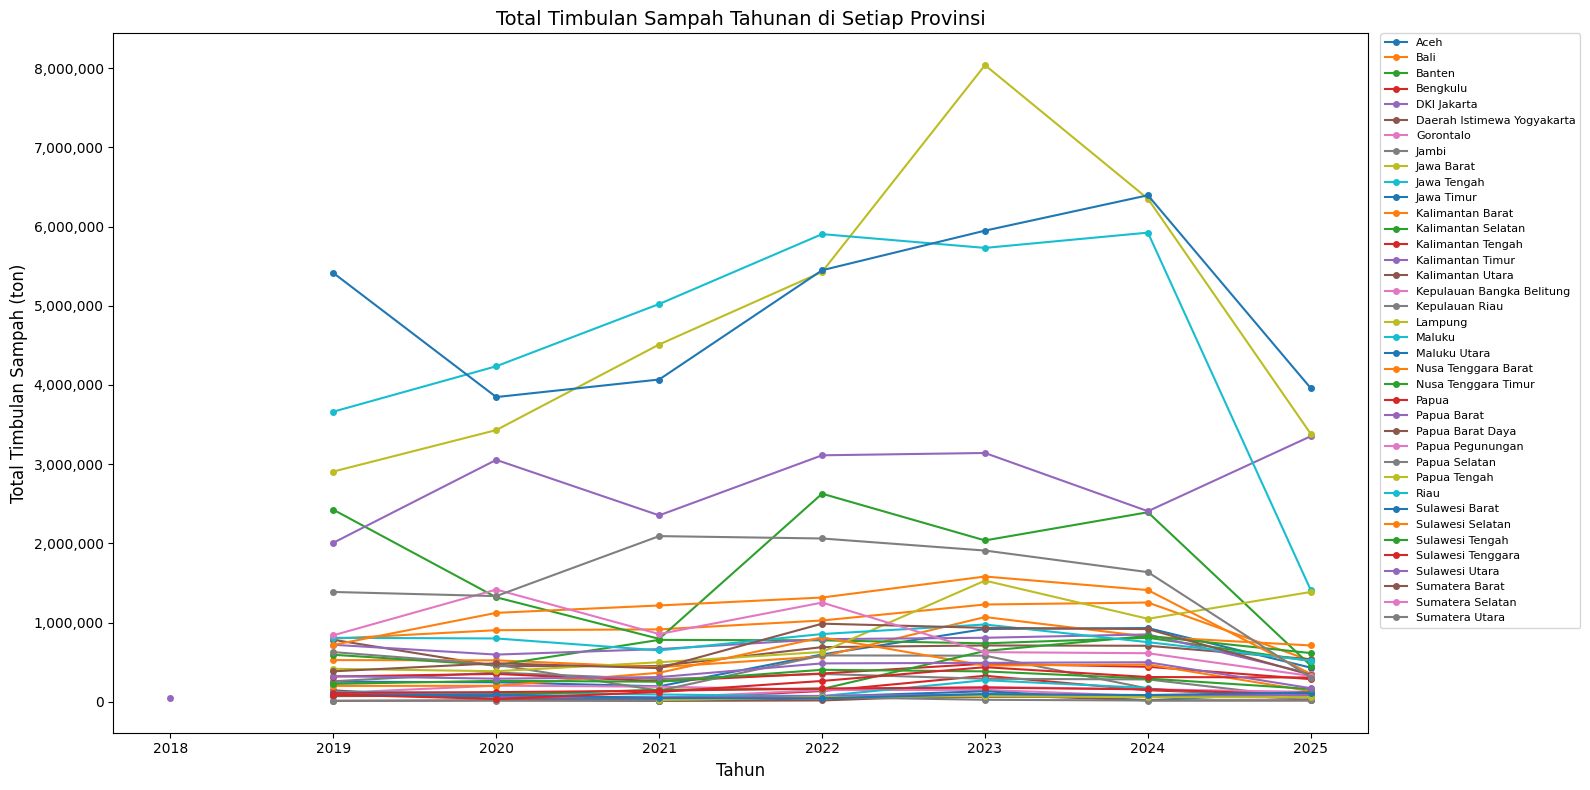

In [14]:
print("=" * 60)
print("ANALISIS 5: Grafik Tren Total Sampah per Provinsi")
print("=" * 60)

pivot_data = total_per_prov_tahun.pivot(
    index='Tahun', columns='Provinsi', values='Total Sampah (ton)'
)

plt.figure(figsize=(16, 8))

for provinsi in pivot_data.columns:
    plt.plot(
        pivot_data.index,
        pivot_data[provinsi],
        marker='o',
        label=provinsi,
        linewidth=1.5,
        markersize=4
    )

plt.xticks(sorted(total_per_prov_tahun['Tahun'].unique()))
plt.gca().yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{int(x):,}")
)

plt.xlabel('Tahun', fontsize=12)
plt.ylabel('Total Timbulan Sampah (ton)', fontsize=12)
plt.title('Total Timbulan Sampah Tahunan di Setiap Provinsi', fontsize=14)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left',
           borderaxespad=0, fontsize=8)
plt.tight_layout()
plt.show()

# **Analisis 6 — Kategorisasi & Bar Chart**

ANALISIS 6: Kategorisasi & Visualisasi Rata-rata Sampah

Hasil kategorisasi:
  [MERAH ] Jawa Timur               :    5,011,268 ton
  [MERAH ] Jawa Barat               :    4,863,657 ton
  [MERAH ] Jawa Tengah              :    4,555,351 ton
  [MERAH ] DKI Jakarta              :    2,775,961 ton
  [MERAH ] Banten                   :    1,722,558 ton
  [MERAH ] Sumatera Utara           :    1,533,191 ton
  [MERAH ] Sulawesi Selatan         :    1,103,317 ton
  [MERAH ] Bali                     :      949,868 ton
  [MERAH ] Sumatera Selatan         :      848,180 ton
  [MERAH ] Lampung                  :      843,134 ton
  [MERAH ] Riau                     :      766,765 ton
  [ORANYE] Kalimantan Timur         :      684,434 ton
  [ORANYE] Kalimantan Selatan       :      668,863 ton
  [ORANYE] Kalimantan Barat         :      667,199 ton
  [ORANYE] Sumatera Barat           :      639,869 ton
  [ORANYE] Daerah Istimewa Yogyakarta:      619,706 ton
  [ORANYE] Aceh                     :     

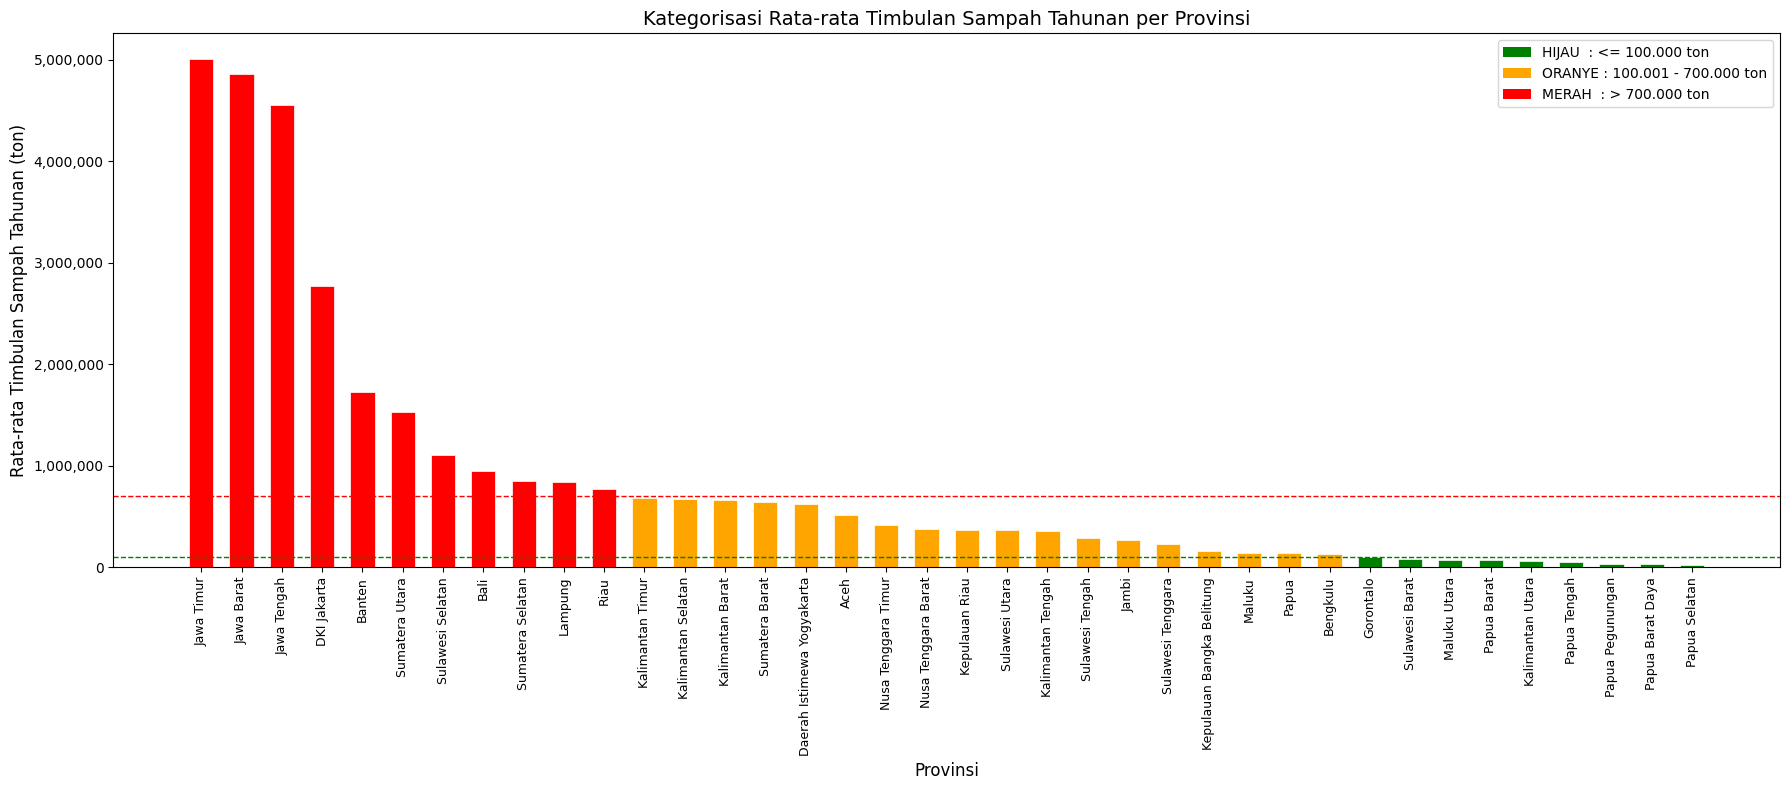

In [15]:
print("=" * 60)
print("ANALISIS 6: Kategorisasi & Visualisasi Rata-rata Sampah")
print("=" * 60)

def kategorikan(rerata):
    if rerata <= 100_000:
        return 'HIJAU'
    elif rerata <= 700_000:
        return 'ORANYE'
    else:
        return 'MERAH'

rerata_per_prov['Kategori'] = rerata_per_prov['Rata-rata Sampah (ton)'].apply(kategorikan)

warna_map = {'HIJAU': 'green', 'ORANYE': 'orange', 'MERAH': 'red'}
color_list = [warna_map[k] for k in rerata_per_prov['Kategori']]

print("\nHasil kategorisasi:")
for _, row in rerata_per_prov.iterrows():
    print(f"  [{row['Kategori']:<6}] {row['Provinsi']:<25}: "
          f"{row['Rata-rata Sampah (ton)']:>12,} ton")

plt.figure(figsize=(18, 8))
plt.bar(
    rerata_per_prov['Provinsi'],
    rerata_per_prov['Rata-rata Sampah (ton)'],
    color=color_list,
    width=0.6,
    edgecolor='white',
    linewidth=0.5
)

plt.axhline(y=100_000, color='green',  linestyle='--', linewidth=1,
            label='Batas HIJAU (100.000)')
plt.axhline(y=700_000, color='red',    linestyle='--', linewidth=1,
            label='Batas MERAH (700.000)')

plt.xticks(rotation=90, fontsize=9)
plt.gca().yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{int(x):,}")
)

plt.xlabel('Provinsi', fontsize=12)
plt.ylabel('Rata-rata Timbulan Sampah Tahunan (ton)', fontsize=12)
plt.title('Kategorisasi Rata-rata Timbulan Sampah Tahunan per Provinsi', fontsize=14)

from matplotlib.patches import Patch
legend_el = [
    Patch(facecolor='green',  label='HIJAU  : <= 100.000 ton'),
    Patch(facecolor='orange', label='ORANYE : 100.001 - 700.000 ton'),
    Patch(facecolor='red',    label='MERAH  : > 700.000 ton'),
]
plt.legend(handles=legend_el, loc='upper right', fontsize=10)
plt.tight_layout()
plt.show()